In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv("../data/banksim_clean.csv")
df.head()

,step,customer,age,gender,merchant,category,amount,fraud,age_group,day,week,month,fraud_label
0,0,C1093826151,4,Male,M348934600,Transportation,4.55,0,46-55,0,1,1,Normal
1,0,C352968107,2,Male,M348934600,Transportation,39.68,0,26-35,0,1,1,Normal
2,0,C2054744914,4,Female,M1823072687,Transportation,26.89,0,46-55,0,1,1,Normal
3,0,C1760612790,3,Male,M348934600,Transportation,17.25,0,36-45,0,1,1,Normal
4,0,C757503768,5,Male,M348934600,Transportation,35.72,0,56-65,0,1,1,Normal


In [2]:
df["category"] = df["category"].replace({
    "Otherservices": "Other Services",
    "Hotelservices": "Hotel Services"
})
df["category"].unique()

<StringArray>
[    'Transportation',             'Health',     'Other Services',
               'Food',     'Hotel Services', 'Bars & Restaurants',
               'Tech',      'Sports & Toys',  'Wellness & Beauty',
              'Hyper',            'Fashion',               'Home',
           'Contents',             'Travel',            'Leisure']
Length: 15, dtype: str

In [3]:
total_txn     = len(df)
fraud_txn     = df["fraud"].sum()
fraud_rate    = fraud_txn / total_txn * 100
total_amt     = df["amount"].sum()
fraud_amt     = df.loc[df["fraud"] == 1, "amount"].sum()
fraud_amt_pct = fraud_amt / total_amt * 100

print(f"Total transactions  : {total_txn:,}")
print(f"Fraud transactions  : {fraud_txn:,}")
print(f"Fraud rate          : {fraud_rate:.2f}%")
print(f"Total amount        : {total_amt:,.0f}")
print(f"Amount lost to fraud: {fraud_amt:,.0f}  ({fraud_amt_pct:.1f}% of all money)")

Total transactions  : 594,643
Fraud transactions  : 7,200
Fraud rate          : 1.21%
Total amount        : 22,531,104
Amount lost to fraud: 3,822,671  (17.0% of all money)


In [4]:
cat = df.groupby("category").agg(
    transactions=("fraud", "size"),
    fraud_count=("fraud", "sum"),
    fraud_rate=("fraud", "mean")
)
cat["fraud_rate"] = cat["fraud_rate"] * 100
cat["fraud_amount"] = df[df["fraud"] == 1].groupby("category")["amount"].sum()
cat["fraud_amount"] = cat["fraud_amount"].fillna(0)
cat = cat.sort_values("fraud_rate", ascending=False)
cat

,transactions,fraud_count,fraud_rate,fraud_amount
category,,,,
Leisure,499,474,94.99,"142,335.98"
Travel,728,578,79.40,"1,537,944.06"
Sports & Toys,4002,1982,49.53,"684,517.02"
Hotel Services,1744,548,31.42,"231,159.19"
Other Services,912,228,25.00,"72,155.07"
Home,1986,302,15.21,"138,160.42"
Health,16133,1696,10.51,"690,325.15"
Tech,2370,158,6.67,"65,613.31"
Wellness & Beauty,15086,718,4.76,"164,725.38"


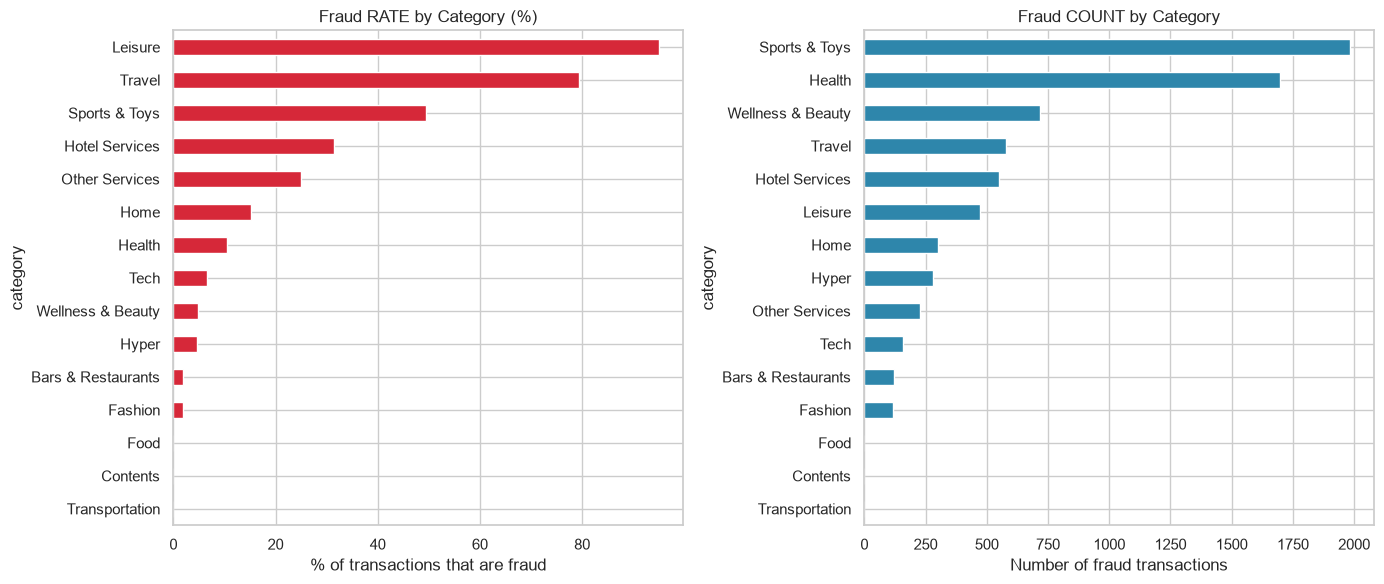

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cat["fraud_rate"].sort_values().plot(kind="barh", ax=axes[0], color="#d62839")
axes[0].set_title("Fraud RATE by Category (%)")
axes[0].set_xlabel("% of transactions that are fraud")

cat["fraud_count"].sort_values().plot(kind="barh", ax=axes[1], color="#2e86ab")
axes[1].set_title("Fraud COUNT by Category")
axes[1].set_xlabel("Number of fraud transactions")

plt.tight_layout()
plt.savefig("../images/fraud_by_category.png", dpi=150, bbox_inches="tight")
plt.show()


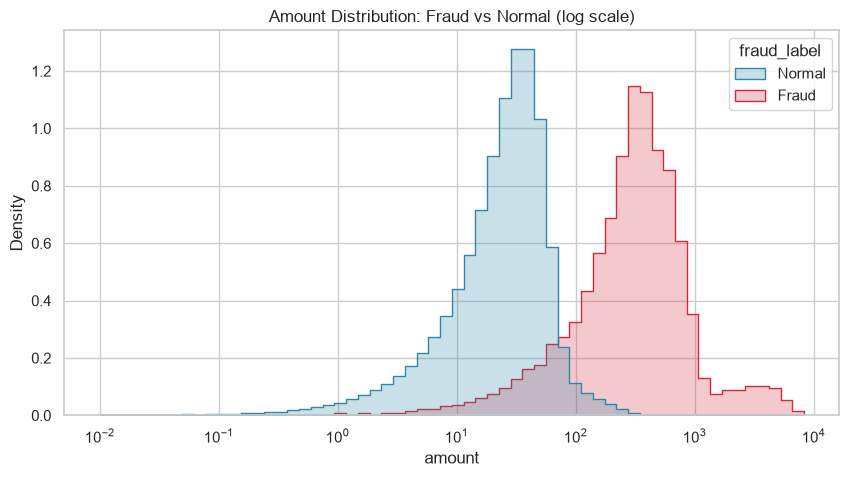

In [6]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="amount", hue="fraud_label", bins=60,
             log_scale=True, element="step", stat="density", common_norm=False,
             palette={"Normal": "#2e86ab", "Fraud": "#d62839"})
plt.title("Amount Distribution: Fraud vs Normal (log scale)")
plt.show()

In [7]:
bins   = [-0.01, 10, 25, 50, 100, 250, 500, 1000, 10000]
labels = ["0-10", "10-25", "25-50", "50-100", "100-250", "250-500", "500-1000", "1000+"]
df["amount_bucket"] = pd.cut(df["amount"], bins=bins, labels=labels)

bucket = df.groupby("amount_bucket", observed=True)["fraud"].agg(["size", "sum", "mean"])
bucket["mean"] = bucket["mean"] * 100
bucket.columns = ["transactions", "fraud_count", "fraud_rate_%"]
bucket

,transactions,fraud_count,fraud_rate_%
amount_bucket,,,
0-10,107469,115,0.11
10-25,168847,172,0.10
25-50,217600,302,0.14
50-100,80172,550,0.69
100-250,15045,1644,10.93
250-500,3346,2341,69.96
500-1000,1526,1469,96.26
1000+,638,607,95.14


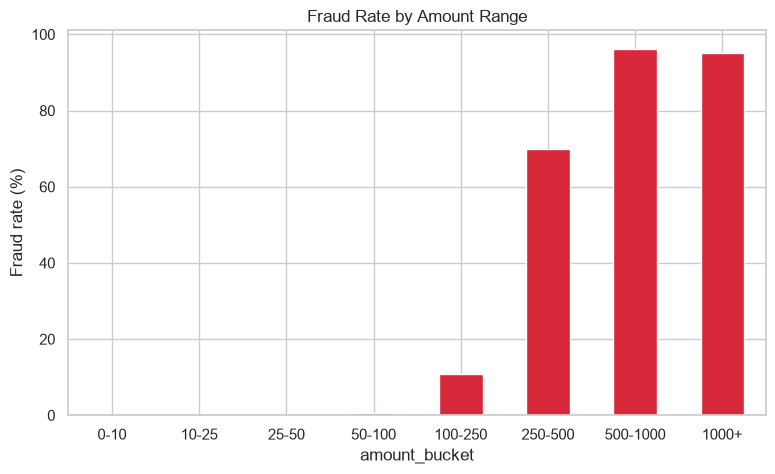

In [8]:
bucket["fraud_rate_%"].plot(kind="bar", figsize=(9, 5), color="#d62839")
plt.title("Fraud Rate by Amount Range")
plt.ylabel("Fraud rate (%)")
plt.xticks(rotation=0)
plt.show()

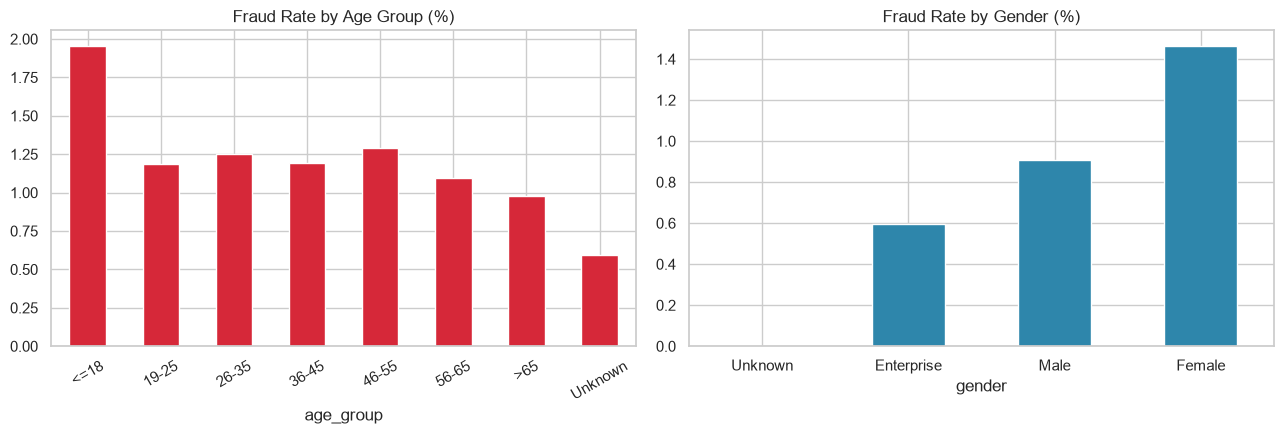

In [9]:
age_order = ["<=18", "19-25", "26-35", "36-45", "46-55", "56-65", ">65", "Unknown"]

age = df.groupby("age_group")["fraud"].mean().reindex(age_order) * 100
gen = df.groupby("gender")["fraud"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
age.plot(kind="bar", ax=axes[0], color="#d62839")
axes[0].set_title("Fraud Rate by Age Group (%)")
axes[0].tick_params(axis="x", rotation=30)

gen.sort_values().plot(kind="bar", ax=axes[1], color="#2e86ab")
axes[1].set_title("Fraud Rate by Gender (%)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

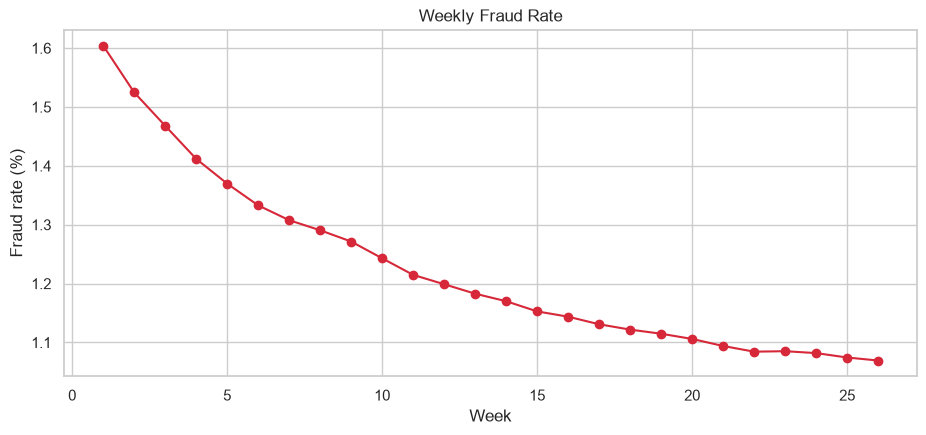

In [10]:
weekly = df.groupby("week").agg(
    transactions=("fraud", "size"),
    fraud_count=("fraud", "sum"),
    fraud_rate=("fraud", "mean")
)
weekly["fraud_rate"] *= 100

plt.figure(figsize=(11, 4.5))
plt.plot(weekly.index, weekly["fraud_rate"], color="#d62839", marker="o")
plt.xlabel("Week")
plt.ylabel("Fraud rate (%)")
plt.title("Weekly Fraud Rate")
plt.show()

In [11]:
merch = df.groupby("merchant").agg(
    transactions=("fraud", "size"),
    fraud_count=("fraud", "sum"),
    fraud_rate=("fraud", "mean")
).sort_values("fraud_count", ascending=False)
merch["fraud_rate"] *= 100
merch.head(10)

,transactions,fraud_count,fraud_rate
merchant,,,
M480139044,3508,1634,46.58
M980657600,1769,1472,83.21
M732195782,608,518,85.20
M1198415165,1580,358,22.66
M3697346,308,290,94.16
M855959430,6098,280,4.59
M1888755466,912,228,25.00
M1873032707,250,216,86.40
M2122776122,341,200,58.65


In [12]:
cust = (df[df["fraud"] == 1].groupby("customer")
          .agg(fraud_count=("fraud", "size"), fraud_amount=("amount", "sum"))
          .sort_values("fraud_count", ascending=False))
print("Customers with at least one fraud:", len(cust), "of", df["customer"].nunique())
cust.head(10)

Customers with at least one fraud: 1483 of 4112


,fraud_count,fraud_amount
customer,,
C1350963410,144,"54,274.78"
C1849046345,127,"59,066.72"
C806399525,125,"80,324.04"
C2004941826,119,"64,165.54"
C1275518867,114,"49,229.18"
C1978250683,110,"50,495.56"
C1572610482,89,"58,203.13"
C381007057,89,"50,245.22"
C910454738,87,"37,143.84"


In [14]:
total_per_cust = df.groupby("customer").size()
top = cust.head(10).copy()
top["total_txn"] = total_per_cust[top.index]
top["fraud_share_%"] = (top["fraud_count"] / top["total_txn"] * 100).round(1)
top

,fraud_count,fraud_amount,total_txn,fraud_share_%
customer,,,,
C1350963410,144,"54,274.78",191,75.40
C1849046345,127,"59,066.72",171,74.30
C806399525,125,"80,324.04",237,52.70
C2004941826,119,"64,165.54",126,94.40
C1275518867,114,"49,229.18",252,45.20
C1978250683,110,"50,495.56",265,41.50
C1572610482,89,"58,203.13",101,88.10
C381007057,89,"50,245.22",100,89.00
C910454738,87,"37,143.84",92,94.60
